# 02 eda
# EDA 1 – Phân tích tín hiệu IMU theo thời gian

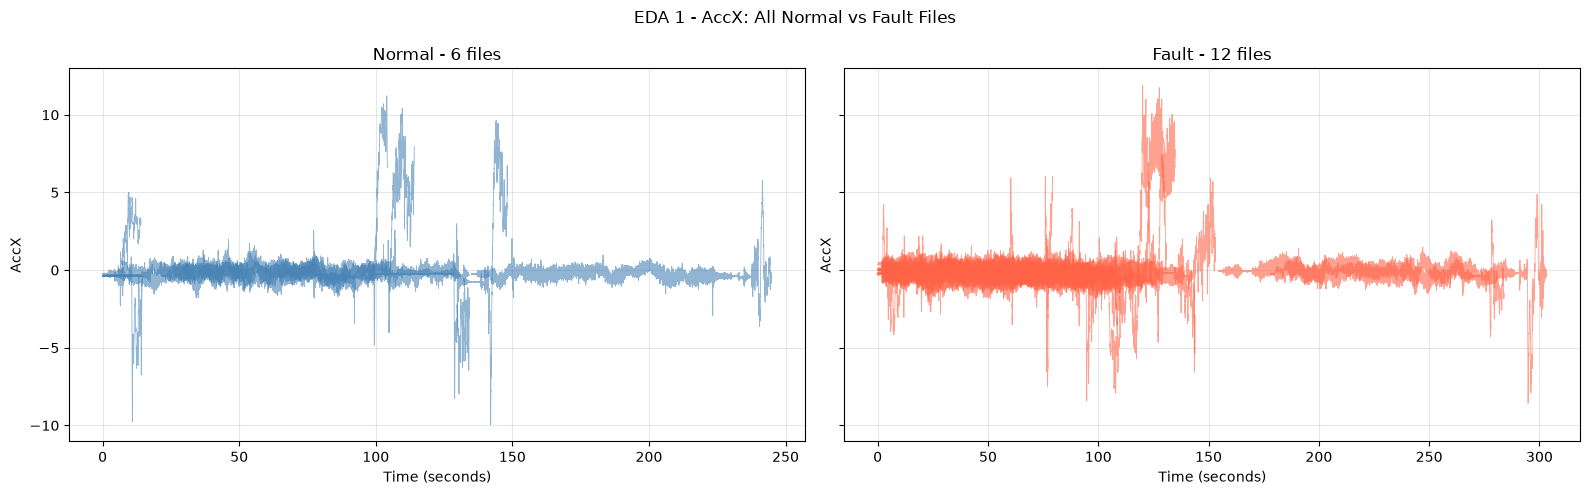

In [14]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Đọc dữ liệu đã gộp
df_uav = pd.read_csv("../data/processed/imu_combined.csv")

# Sắp xếp theo file và thời gian
df_uav = df_uav.sort_values(
    ["source_file", "TimeUS"]
).copy()

# Tính thời gian tương đối cho từng file
df_uav["Time_s"] = (
    df_uav["TimeUS"]
    - df_uav.groupby("source_file")["TimeUS"].transform("min")
) / 1_000_000

# Tách nhóm Normal và Fault
normal = df_uav[df_uav["Label"] == 0]
fault = df_uav[df_uav["Label"] == 1]

# Vẽ AccX của toàn bộ 18 file
fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 5),
    sharey=True
)

for ax, (label, group, title, color) in zip(
    axes,
    [
        (0, normal, "Normal - 6 files", "steelblue"),
        (1, fault, "Fault - 12 files", "tomato")
    ]
):
    for file_name, data in group.groupby("source_file"):

        # Không nối đường qua khoảng trống thời gian lớn
        data = data.sort_values("Time_s").copy()
        gaps = data["Time_s"].diff()
        typical_gap = gaps[gaps > 0].median()

        if pd.notna(typical_gap):
            data.loc[
                gaps > 10 * typical_gap, "AccX"
            ] = np.nan

        ax.plot(
            data["Time_s"],
            data["AccX"],
            linewidth=0.6,
            alpha=0.6,
            color=color
        )

    ax.set_title(title)
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("AccX")
    ax.grid(alpha=0.3)

plt.suptitle("EDA 1 - AccX: All Normal vs Fault Files")
plt.tight_layout()
plt.show()


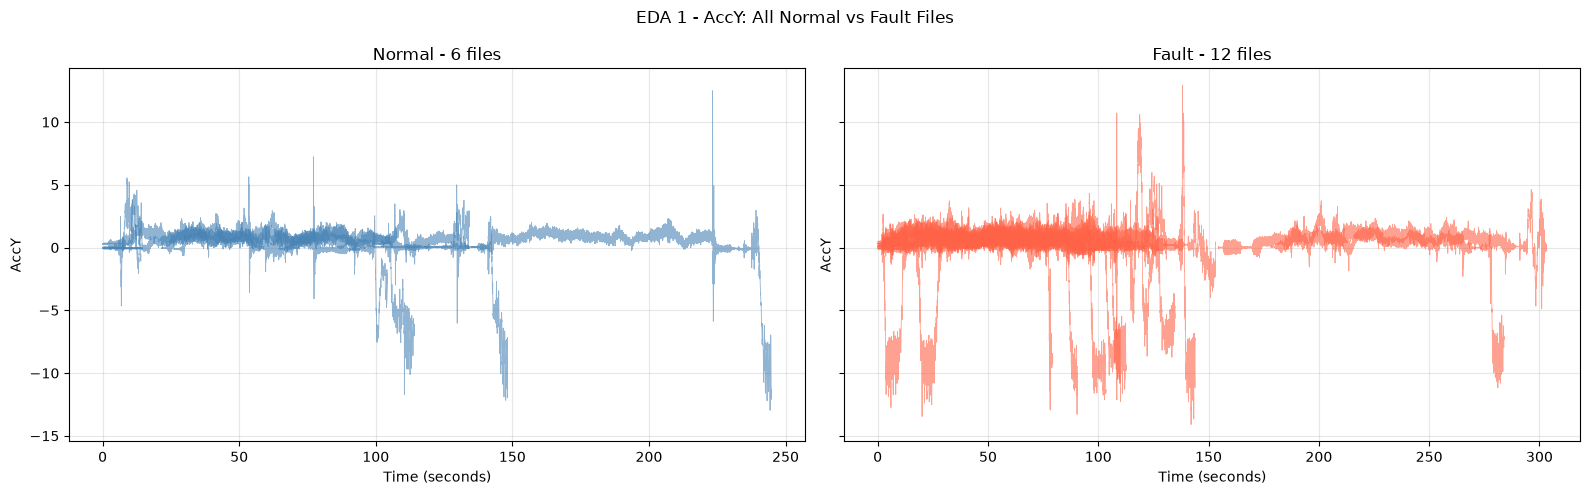

In [15]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Đọc dữ liệu
df_uav = pd.read_csv("../data/processed/imu_combined.csv")

# 2. Sắp xếp dữ liệu
df_uav = df_uav.sort_values(
    ["source_file", "TimeUS"]
).copy()

# 3. Tính thời gian tương đối cho từng file
df_uav["Time_s"] = (
    df_uav["TimeUS"]
    - df_uav.groupby("source_file")["TimeUS"].transform("min")
) / 1_000_000

# 4. Tách hai nhóm
normal = df_uav[df_uav["Label"] == 0]
fault = df_uav[df_uav["Label"] == 1]

# 5. Vẽ biểu đồ AccY
fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 5),
    sharey=True
)

for ax, (group, title, color) in zip(
    axes,
    [
        (normal, "Normal - 6 files", "steelblue"),
        (fault, "Fault - 12 files", "tomato")
    ]
):
    for file_name, data in group.groupby("source_file"):

        data = data.sort_values("Time_s").copy()

        # Ngắt đường khi có khoảng trống thời gian lớn
        gaps = data["Time_s"].diff()
        typical_gap = gaps[gaps > 0].median()

        if pd.notna(typical_gap):
            data.loc[
                gaps > 10 * typical_gap, "AccY"
            ] = np.nan

        ax.plot(
            data["Time_s"],
            data["AccY"],
            color=color,
            linewidth=0.6,
            alpha=0.6
        )

    ax.set_title(title)
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("AccY")
    ax.grid(alpha=0.3)

plt.suptitle("EDA 1 - AccY: All Normal vs Fault Files")
plt.tight_layout()
plt.show()


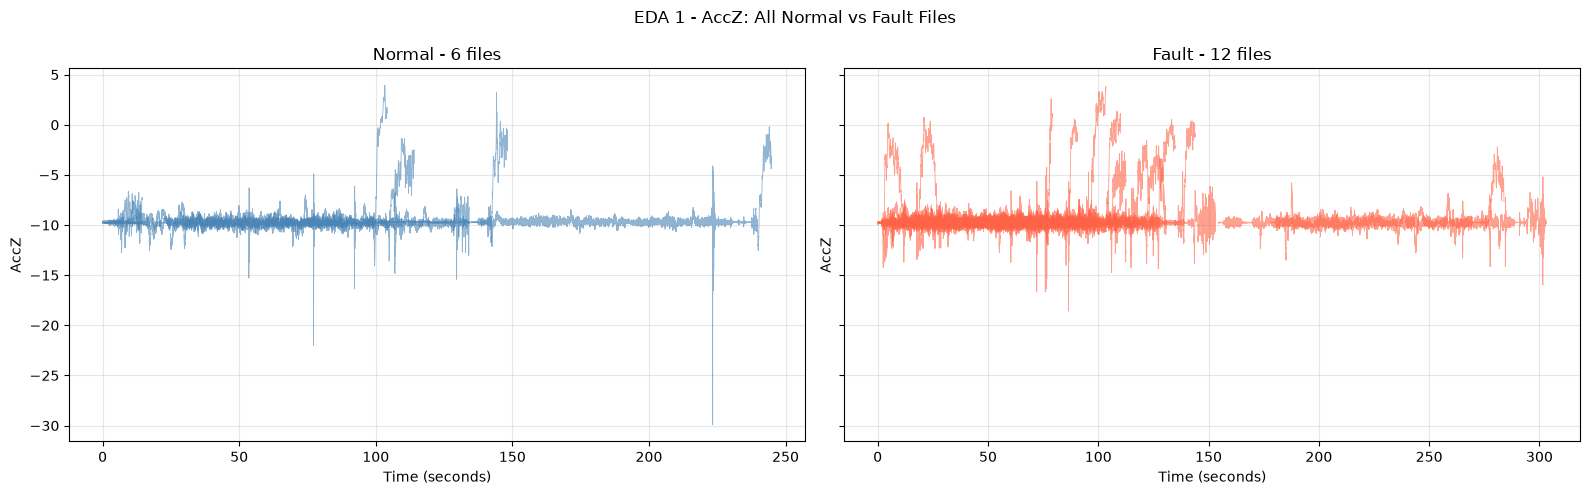

In [16]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Đọc dữ liệu UAV
df_uav = pd.read_csv("../data/processed/imu_combined.csv")

# 2. Sắp xếp dữ liệu theo file và thời gian
df_uav = df_uav.sort_values(
    ["source_file", "TimeUS"]
).copy()

# 3. Tính thời gian tương đối cho từng file
df_uav["Time_s"] = (
    df_uav["TimeUS"]
    - df_uav.groupby("source_file")["TimeUS"].transform("min")
) / 1_000_000

# 4. Tách Normal và Fault
normal = df_uav[df_uav["Label"] == 0]
fault = df_uav[df_uav["Label"] == 1]

# 5. Vẽ Line Chart AccZ
fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 5),
    sharey=True
)

groups = [
    (normal, "Normal - 6 files", "steelblue"),
    (fault, "Fault - 12 files", "tomato")
]

for ax, (group, title, color) in zip(axes, groups):

    for file_name, data in group.groupby("source_file"):

        data = data.sort_values("Time_s").copy()

        # Xác định khoảng trống thời gian lớn
        gaps = data["Time_s"].diff()
        typical_gap = gaps[gaps > 0].median()

        # Ngắt đường vẽ qua khoảng trống lớn
        if pd.notna(typical_gap):
            data.loc[
                gaps > 10 * typical_gap, "AccZ"
            ] = np.nan

        ax.plot(
            data["Time_s"],
            data["AccZ"],
            color=color,
            linewidth=0.6,
            alpha=0.6
        )

    ax.set_title(title)
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("AccZ")
    ax.grid(alpha=0.3)

plt.suptitle("EDA 1 - AccZ: All Normal vs Fault Files")
plt.tight_layout()
plt.show()


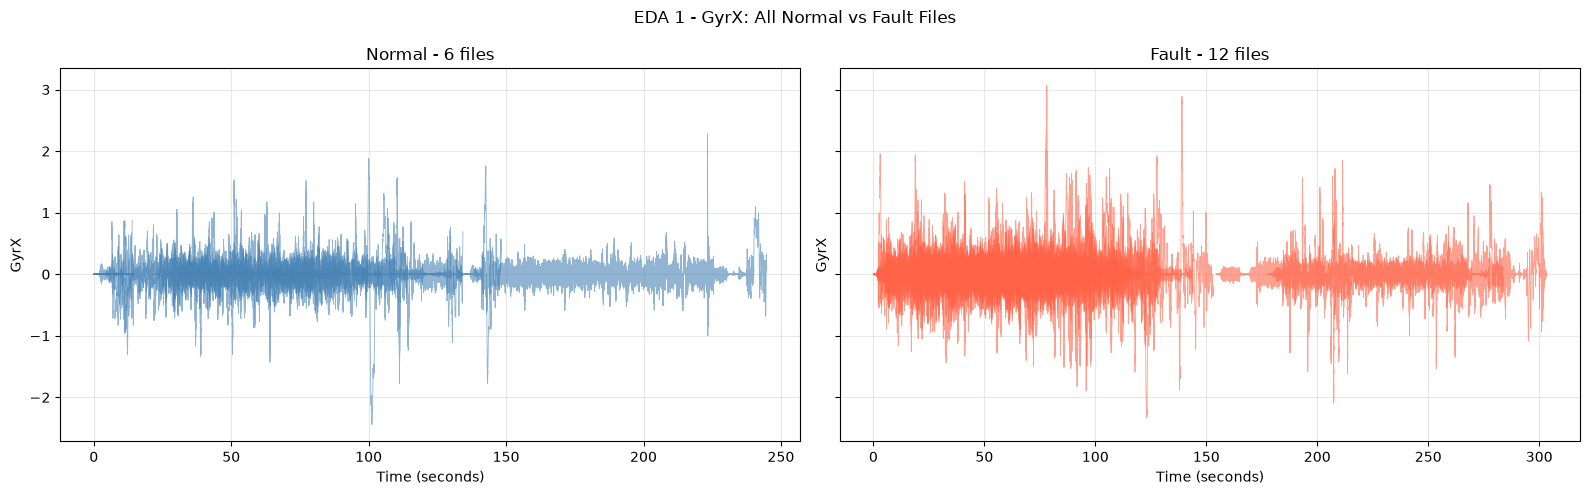

In [17]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Đọc dữ liệu
df_uav = pd.read_csv("../data/processed/imu_combined.csv")

# 2. Sắp xếp theo file và thời gian
df_uav = df_uav.sort_values(
    ["source_file", "TimeUS"]
).copy()

# 3. Tính thời gian tương đối cho từng file
df_uav["Time_s"] = (
    df_uav["TimeUS"]
    - df_uav.groupby("source_file")["TimeUS"].transform("min")
) / 1_000_000

# 4. Chia nhóm Normal và Fault
normal = df_uav[df_uav["Label"] == 0]
fault = df_uav[df_uav["Label"] == 1]

# 5. Vẽ biểu đồ GyrX
fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 5),
    sharey=True
)

groups = [
    (normal, "Normal - 6 files", "steelblue"),
    (fault, "Fault - 12 files", "tomato")
]

for ax, (group, title, color) in zip(axes, groups):

    for file_name, data in group.groupby("source_file"):

        data = data.sort_values("Time_s").copy()

        # Kiểm tra khoảng trống thời gian
        gaps = data["Time_s"].diff()
        typical_gap = gaps[gaps > 0].median()

        # Ngắt đường vẽ nếu khoảng trống quá lớn
        if pd.notna(typical_gap):
            data.loc[
                gaps > 10 * typical_gap, "GyrX"
            ] = np.nan

        ax.plot(
            data["Time_s"],
            data["GyrX"],
            color=color,
            linewidth=0.6,
            alpha=0.6
        )

    ax.set_title(title)
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("GyrX")
    ax.grid(alpha=0.3)

plt.suptitle("EDA 1 - GyrX: All Normal vs Fault Files")
plt.tight_layout()
plt.show()


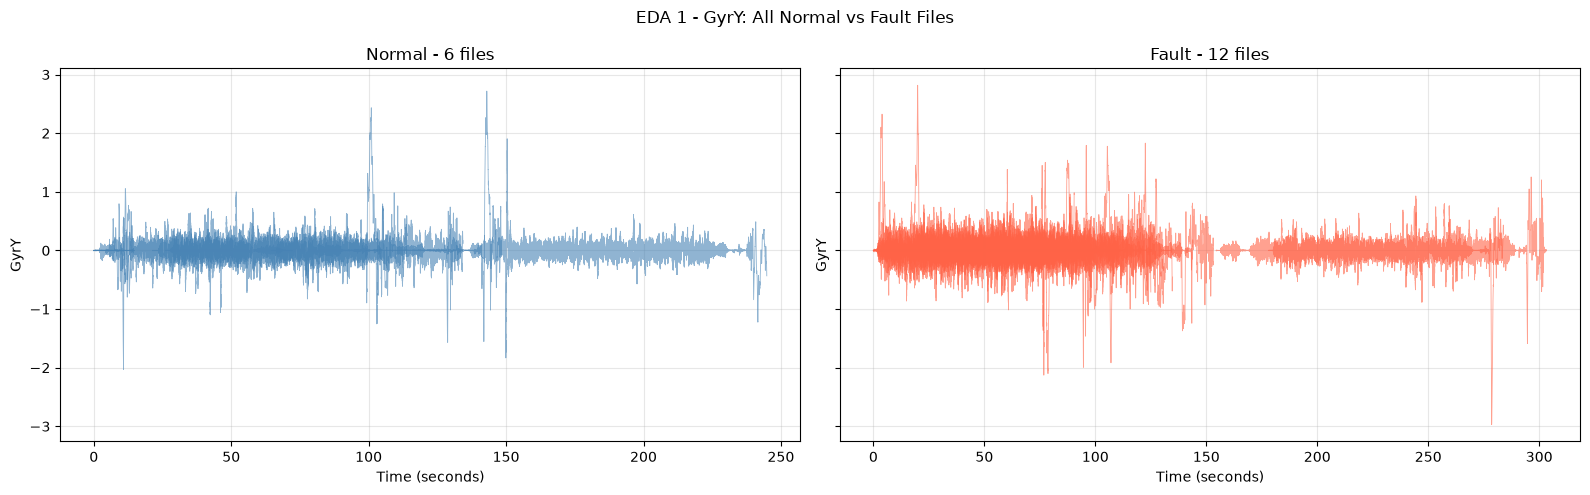

In [18]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Đọc dữ liệu
df_uav = pd.read_csv("../data/processed/imu_combined.csv")

# 2. Sắp xếp dữ liệu theo file và thời gian
df_uav = df_uav.sort_values(
    ["source_file", "TimeUS"]
).copy()

# 3. Tính thời gian tương đối cho từng file
df_uav["Time_s"] = (
    df_uav["TimeUS"]
    - df_uav.groupby("source_file")["TimeUS"].transform("min")
) / 1_000_000

# 4. Chia thành hai nhóm
normal = df_uav[df_uav["Label"] == 0]
fault = df_uav[df_uav["Label"] == 1]

# 5. Vẽ biểu đồ GyrY
fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 5),
    sharey=True
)

groups = [
    (normal, "Normal - 6 files", "steelblue"),
    (fault, "Fault - 12 files", "tomato")
]

for ax, (group, title, color) in zip(axes, groups):

    for file_name, data in group.groupby("source_file"):

        data = data.sort_values("Time_s").copy()

        # Tính khoảng cách giữa các mẫu đo
        gaps = data["Time_s"].diff()
        typical_gap = gaps[gaps > 0].median()

        # Ngắt đường vẽ nếu có khoảng trống lớn
        if pd.notna(typical_gap):
            data.loc[
                gaps > 10 * typical_gap, "GyrY"
            ] = np.nan

        ax.plot(
            data["Time_s"],
            data["GyrY"],
            color=color,
            linewidth=0.6,
            alpha=0.6
        )

    ax.set_title(title)
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("GyrY")
    ax.grid(alpha=0.3)

plt.suptitle("EDA 1 - GyrY: All Normal vs Fault Files")
plt.tight_layout()
plt.show()


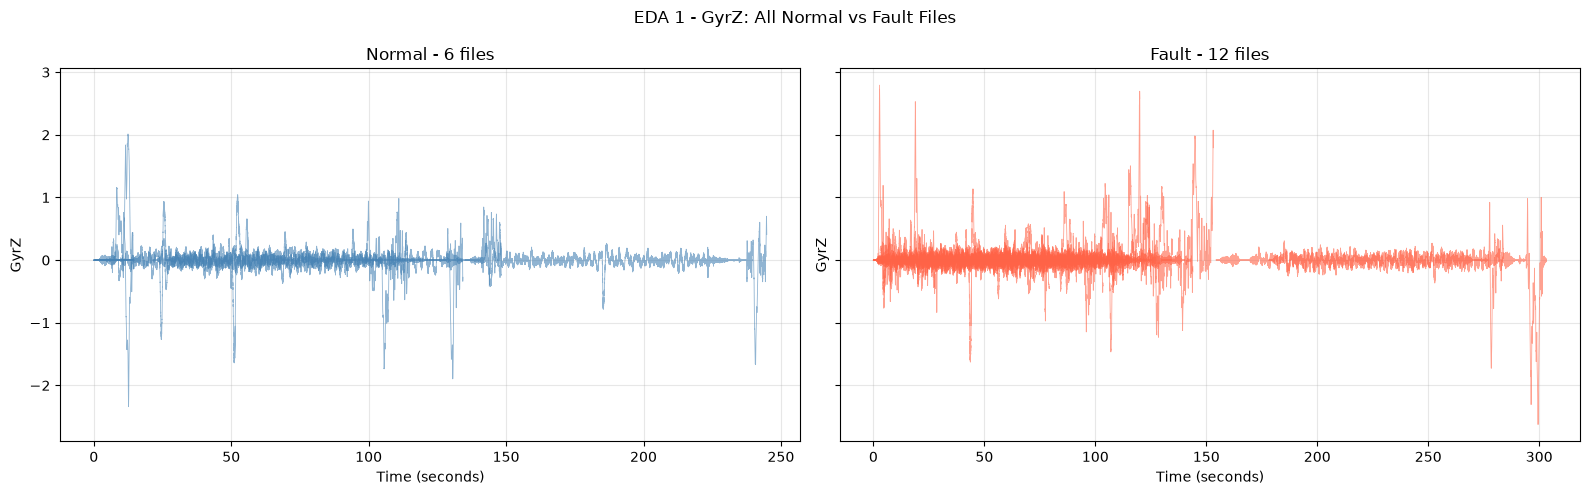

In [19]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Đọc dữ liệu
df_uav = pd.read_csv("../data/processed/imu_combined.csv")

# 2. Sắp xếp theo file và thời gian
df_uav = df_uav.sort_values(
    ["source_file", "TimeUS"]
).copy()

# 3. Tính thời gian tương đối cho từng file
df_uav["Time_s"] = (
    df_uav["TimeUS"]
    - df_uav.groupby("source_file")["TimeUS"].transform("min")
) / 1_000_000

# 4. Tách nhóm Normal và Fault
normal = df_uav[df_uav["Label"] == 0]
fault = df_uav[df_uav["Label"] == 1]

# 5. Vẽ Line Chart GyrZ
fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 5),
    sharey=True
)

groups = [
    (normal, "Normal - 6 files", "steelblue"),
    (fault, "Fault - 12 files", "tomato")
]

for ax, (group, title, color) in zip(axes, groups):

    for file_name, data in group.groupby("source_file"):

        data = data.sort_values("Time_s").copy()

        # Kiểm tra khoảng trống thời gian
        gaps = data["Time_s"].diff()
        typical_gap = gaps[gaps > 0].median()

        # Ngắt đường vẽ tại khoảng trống lớn
        if pd.notna(typical_gap):
            data.loc[
                gaps > 10 * typical_gap, "GyrZ"
            ] = np.nan

        ax.plot(
            data["Time_s"],
            data["GyrZ"],
            color=color,
            linewidth=0.6,
            alpha=0.6
        )

    ax.set_title(title)
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("GyrZ")
    ax.grid(alpha=0.3)

plt.suptitle("EDA 1 - GyrZ: All Normal vs Fault Files")
plt.tight_layout()
plt.show()


In [20]:
# EDA 2 – Phân tích phân phối và Thống kê mô tả

C:\Users\DELL\AppData\Local\Temp\ipykernel_19732\3295131630.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[i].set_xticklabels(['Normal (0)', 'Fault (1)'])
C:\Users\DELL\AppData\Local\Temp\ipykernel_19732\3295131630.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[i].set_xticklabels(['Normal (0)', 'Fault (1)'])
C:\Users\DELL\AppData\Local\Temp\ipykernel_19732\3295131630.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[i].set_xticklabels(['Normal (0)', 'Fault (1)'])
C:\Users\DELL\AppData\Local\Temp\ipykernel_19732\3295131630.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ti

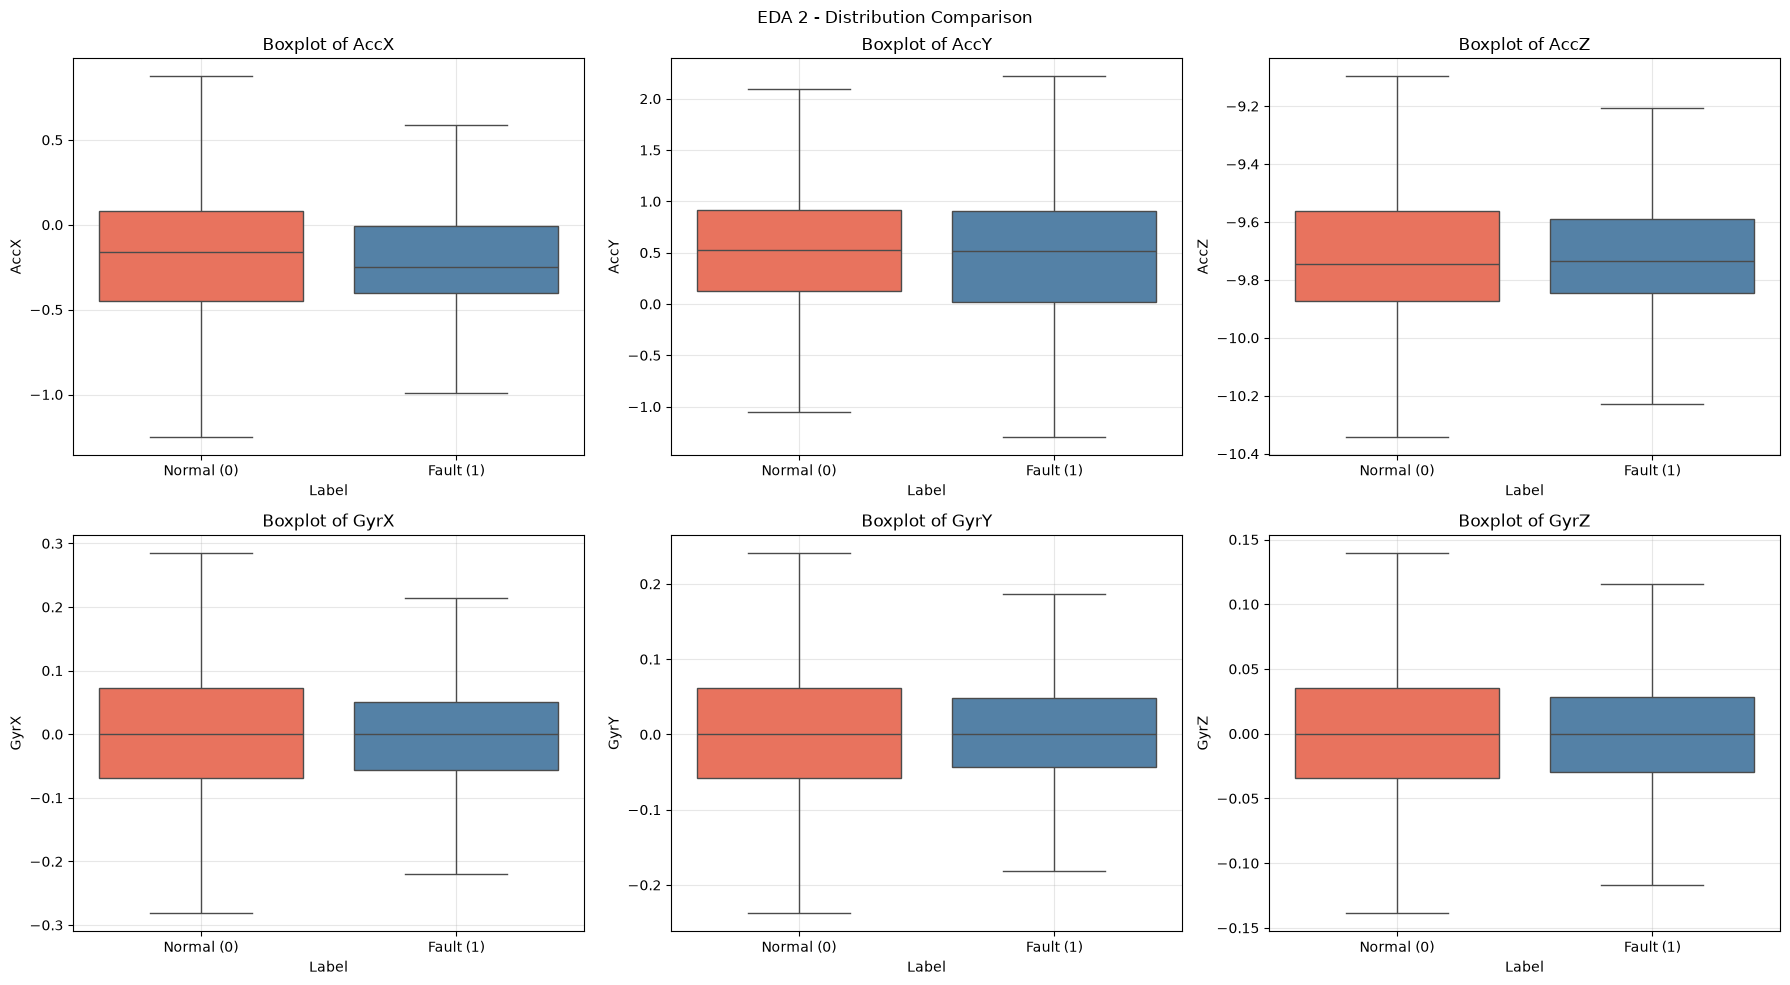

--- BẢNG THỐNG KÊ MÔ TẢ TÍN HIỆU IMU (NORMAL VS FAULT) ---


Normal (0)  Fault (1)
AccX mean       -0.0705    -0.1205
     std         1.3516     1.1015
     median     -0.2487    -0.1621
     iqr         0.3946     0.5306
AccY mean        0.3094     0.2148
     std         1.4627     1.9274
     median      0.5196     0.5267
     iqr         0.8775     0.7862
AccZ mean       -9.4883    -9.4091
     std         1.4094     1.6396
     median     -9.7332    -9.7445
     iqr         0.2552     0.3108
GyrX mean       -0.0047     0.0058
     std         0.2260     0.2400
     median     -0.0004    -0.0001
     iqr         0.1083     0.1416
GyrY mean        0.0083     0.0044
     std         0.2078     0.2125
     median      0.0002     0.0001
     iqr         0.0920     0.1196
GyrZ mean       -0.0016     0.0066
     std         0.2005     0.1898
     median     -0.0004    -0.0001
     iqr         0.0581     0.0696

In [22]:
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

# Ép kiểu cột Label sang dạng chuỗi (string) để đồng bộ tuyệt đối với bảng màu
df_uav['Label'] = df_uav['Label'].astype(str)

features = ['AccX', 'AccY', 'AccZ', 'GyrX', 'GyrY', 'GyrZ']
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

# Đã bổ sung hue='Label', legend=False và cập nhật khóa palette sang chuỗi '0', '1'
for i, col in enumerate(features):
    sns.boxplot(data=df_uav, x='Label', y=col, ax=axes[i], 
                hue='Label', legend=False,
                palette={'0': 'steelblue', '1': 'tomato'}, showfliers=False)
    axes[i].set_title(f'Boxplot of {col}')
    axes[i].set_xticklabels(['Normal (0)', 'Fault (1)'])
    axes[i].grid(alpha=0.3)

plt.suptitle("EDA 2 - Distribution Comparison")
plt.tight_layout()
plt.show()

# Tính toán bảng thống kê mô tả
print("--- BẢNG THỐNG KÊ MÔ TẢ TÍN HIỆU IMU (NORMAL VS FAULT) ---")

def iqr(x):
    return np.percentile(x, 75) - np.percentile(x, 25)

stats_table = df_uav.groupby('Label')[features].agg(['mean', 'std', 'median', iqr]).T
stats_table = stats_table.round(4)
stats_table.columns = ['Normal (0)', 'Fault (1)']
display(stats_table)

In [ ]:
# EDA 3 – PHÂN TÍCH TƯƠNG QUAN GIỮA CÁC KÊNH IMU

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Đọc dữ liệu đã gộp
df_uav = pd.read_csv("../data/processed/imu_combined.csv")

# Chọn 6 kênh cảm biến IMU
features = [
    "AccX", "AccY", "AccZ",
    "GyrX", "GyrY", "GyrZ"
]

print("Kích thước dữ liệu:", df_uav.shape)

print("\nSố file theo trạng thái:")
print(df_uav.groupby("Label")["source_file"].nunique())

print("\nSố giá trị thiếu:")
print(df_uav[features].isna().sum())


Kích thước dữ liệu: (767763, 9)

Số file theo trạng thái:
Label
0     6
1    12
Name: source_file, dtype: int64

Số giá trị thiếu:
AccX    0
AccY    0
AccZ    0
GyrX    0
GyrY    0
GyrZ    0
dtype: int64


In [2]:

# Tách hai nhóm
normal = df_uav[df_uav["Label"] == 0]
fault = df_uav[df_uav["Label"] == 1]

# Tính ma trận tương quan
corr_normal = normal[features].corr(method="pearson")
corr_fault = fault[features].corr(method="pearson")

print("=== CORRELATION NORMAL ===")
print(corr_normal.round(2))

print("\n=== CORRELATION FAULT ===")
print(corr_fault.round(2))


=== CORRELATION NORMAL ===
      AccX  AccY  AccZ  GyrX  GyrY  GyrZ
AccX  1.00 -0.55  0.69 -0.15  0.13  0.15
AccY -0.55  1.00 -0.72  0.04 -0.15  0.03
AccZ  0.69 -0.72  1.00 -0.18  0.20 -0.02
GyrX -0.15  0.04 -0.18  1.00 -0.21 -0.13
GyrY  0.13 -0.15  0.20 -0.21  1.00 -0.08
GyrZ  0.15  0.03 -0.02 -0.13 -0.08  1.00

=== CORRELATION FAULT ===
      AccX  AccY  AccZ  GyrX  GyrY  GyrZ
AccX  1.00  0.04  0.15  0.00 -0.11  0.13
AccY  0.04  1.00 -0.79 -0.07 -0.06 -0.02
AccZ  0.15 -0.79  1.00  0.05  0.05  0.03
GyrX  0.00 -0.07  0.05  1.00 -0.05 -0.02
GyrY -0.11 -0.06  0.05 -0.05  1.00  0.15
GyrZ  0.13 -0.02  0.03 -0.02  0.15  1.00


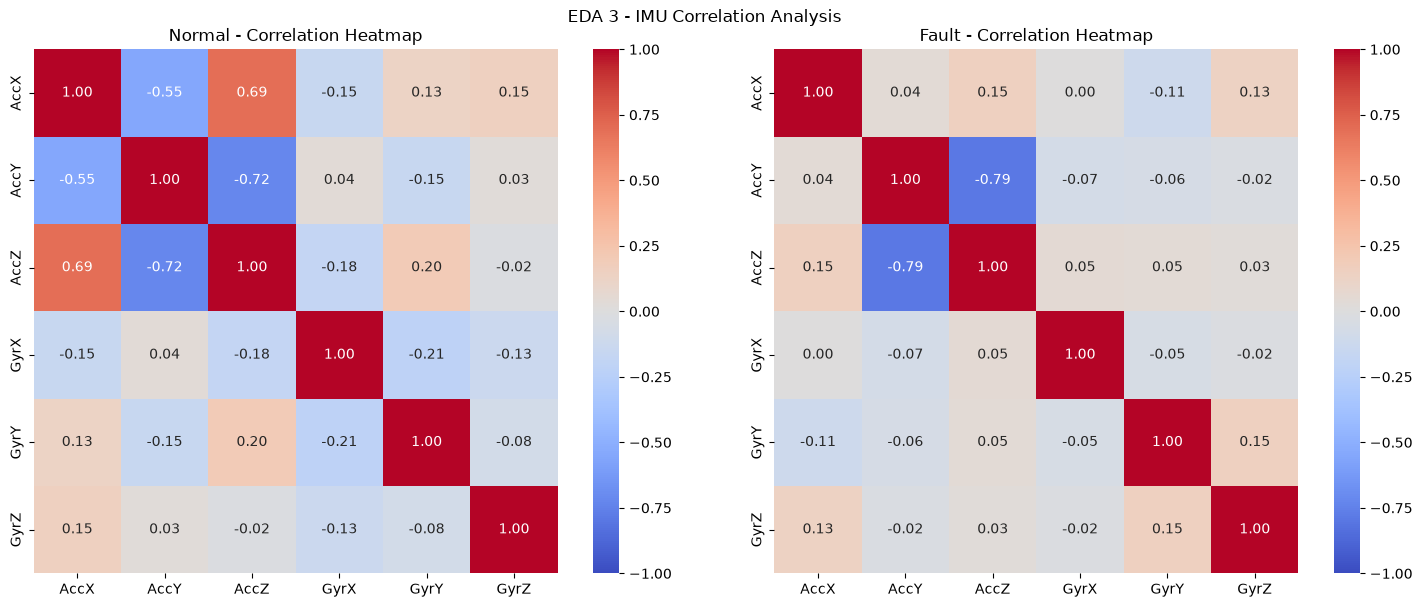

In [4]:

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 6)
)

sns.heatmap(
    corr_normal,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    ax=axes[0]
)

axes[0].set_title("Normal - Correlation Heatmap")

sns.heatmap(
    corr_fault,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    ax=axes[1]
)

axes[1].set_title("Fault - Correlation Heatmap")

plt.suptitle("EDA 3 - IMU Correlation Analysis")
plt.tight_layout()
plt.show()


In [5]:

results = []

for i in range(len(features)):
    for j in range(i + 1, len(features)):

        col1 = features[i]
        col2 = features[j]

        r_normal = corr_normal.loc[col1, col2]
        r_fault = corr_fault.loc[col1, col2]

        results.append({
            "Pair": f"{col1} - {col2}",
            "Normal": r_normal,
            "Fault": r_fault,
            "Difference": r_fault - r_normal,
            "Abs_Difference": abs(r_fault - r_normal)
        })

comparison = pd.DataFrame(results)

comparison = comparison.sort_values(
    "Abs_Difference",
    ascending=False
)

print("=== SO SANH 15 CAP CAM BIEN ===")
print(comparison.round(3).to_string(index=False))


=== SO SANH 15 CAP CAM BIEN ===
       Pair  Normal  Fault  Difference  Abs_Difference
AccX - AccY  -0.550  0.042       0.592           0.592
AccX - AccZ   0.694  0.151      -0.543           0.543
AccX - GyrY   0.128 -0.110      -0.238           0.238
GyrY - GyrZ  -0.083  0.151       0.234           0.234
AccZ - GyrX  -0.177  0.050       0.226           0.226
GyrX - GyrY  -0.215 -0.054       0.160           0.160
AccZ - GyrY   0.198  0.046      -0.152           0.152
AccX - GyrX  -0.150  0.001       0.151           0.151
AccY - GyrX   0.039 -0.074      -0.113           0.113
GyrX - GyrZ  -0.130 -0.018       0.112           0.112
AccY - GyrY  -0.154 -0.062       0.092           0.092
AccY - AccZ  -0.723 -0.793      -0.070           0.070
AccY - GyrZ   0.025 -0.025      -0.050           0.050
AccZ - GyrZ  -0.019  0.027       0.045           0.045
AccX - GyrZ   0.154  0.133      -0.021           0.021


In [6]:

top5 = comparison[
    ["Pair", "Normal", "Fault", "Abs_Difference"]
].head(5)

print("=== TOP 5 CAP THAY DOI NHIEU NHAT ===")
print(top5.round(3).to_string(index=False))


=== TOP 5 CAP THAY DOI NHIEU NHAT ===
       Pair  Normal  Fault  Abs_Difference
AccX - AccY  -0.550  0.042           0.592
AccX - AccZ   0.694  0.151           0.543
AccX - GyrY   0.128 -0.110           0.238
GyrY - GyrZ  -0.083  0.151           0.234
AccZ - GyrX  -0.177  0.050           0.226


In [8]:

# Chọn 3 cặp gia tốc nổi bật
pairs = [
    ("AccX", "AccY"),
    ("AccX", "AccZ"),
    ("AccY", "AccZ")
]

rows = []

for file_name, data in df_uav.groupby("source_file"):

    label = data["Label"].iloc[0]

    for col1, col2 in pairs:

        r = data[col1].corr(data[col2])

        rows.append({
            "File": file_name,
            "Label": label,
            "Pair": f"{col1} - {col2}",
            "Correlation": r
        })

corr_per_file = pd.DataFrame(rows)

print("=== CORRELATION THEO TUNG FILE ===")
print(
    corr_per_file.sort_values(
        ["Pair", "Label", "File"]
    ).round(3).to_string(index=False)
)




=== CORRELATION THEO TUNG FILE ===
           File  Label        Pair  Correlation
  NO_FAULT1.mat      0 AccX - AccY       -0.429
  NO_FAULT2.mat      0 AccX - AccY       -0.221
  NO_FAULT3.mat      0 AccX - AccY        0.051
  NO_FAULT4.mat      0 AccX - AccY       -0.632
  NO_FAULT5.mat      0 AccX - AccY       -0.761
  NO_FAULT6.mat      0 AccX - AccY       -0.860
FAULT_M1_10.mat      1 AccX - AccY       -0.906
 FAULT_M1_5.mat      1 AccX - AccY        0.377
FAULT_M2_10.mat      1 AccX - AccY       -0.486
 FAULT_M2_5.mat      1 AccX - AccY        0.894
FAULT_M3_10.mat      1 AccX - AccY        0.725
 FAULT_M3_5.mat      1 AccX - AccY       -0.496
FAULT_M4_10.mat      1 AccX - AccY        0.078
 FAULT_M4_5.mat      1 AccX - AccY       -0.561
FAULT_M5_10.mat      1 AccX - AccY       -0.371
 FAULT_M5_5.mat      1 AccX - AccY       -0.197
FAULT_M6_10.mat      1 AccX - AccY        0.461
 FAULT_M6_5.mat      1 AccX - AccY        0.419
  NO_FAULT1.mat      0 AccX - AccZ       -0.040
  NO_

In [9]:

summary = (
    corr_per_file
    .groupby(["Pair", "Label"])["Correlation"]
    .agg(["count", "median", "std", "min", "max"])
    .round(3)
)

print("=== TONG HOP CORRELATION THEO FILE ===")
print(summary)


=== TONG HOP CORRELATION THEO FILE ===
                   count  median    std    min    max
Pair        Label                                    
AccX - AccY 0          6  -0.530  0.346 -0.860  0.051
            1         12  -0.059  0.576 -0.906  0.894
AccX - AccZ 0          6   0.477  0.467 -0.040  0.945
            1         12   0.061  0.567 -0.911  0.929
AccY - AccZ 0          6  -0.759  0.518 -0.894  0.275
            1         12  -0.882  0.347 -0.942  0.076


In [10]:

# Lưu bảng so sánh 15 cặp cảm biến
comparison.to_csv(
    "../data/processed/eda3_correlation_comparison.csv",
    index=False
)

# Lưu tương quan từng file
corr_per_file.to_csv(
    "../data/processed/eda3_correlation_by_file.csv",
    index=False
)

print("Đã lưu kết quả EDA 3 thành công!")


Đã lưu kết quả EDA 3 thành công!
